# Data Preparation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import randint, uniform
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split , RandomizedSearchCV
from sklearn.metrics import accuracy_score, recall_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import roc_auc_score, precision_score, f1_score, recall_score

In [4]:
df= pd.read_csv('bank-additional-full.csv', sep= ";")

## Data Understanding

In [5]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
df.info()

In [ ]:
df.isna().sum()

In [6]:
df.duplicated().sum()

np.int64(12)

In [ ]:
df.shape

In [ ]:
df.describe()

In [ ]:
df.describe(include='object')

In [7]:
for column in df.select_dtypes(include='object').columns:
    print(f"Value counts for column '{column}':")
    print(df[column].value_counts())
    print("\n" + "-"*30 + "\n")

Value counts for column 'job':
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

------------------------------

Value counts for column 'marital':
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

------------------------------

Value counts for column 'education':
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

------------------------------

Value counts for column 'default':
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int6

## Data Cleaning & Feature Engineering

In [12]:
#drop duplicate
df= df.drop_duplicates()

In [14]:
df.isna().sum()

,0
age,0
job,330
marital,80
education,1730
default,8596
housing,990
loan,990
contact,0
month,0
day_of_week,0


In [15]:
# Create a new binary column: 0 if never contacted, 1 if contacted
df['was_contacted'] = df['pdays'].apply(lambda x: 0 if x == 999 else 1)

# Verify the change
print(df['was_contacted'].value_counts())

was_contacted
0    39661
1     1515
Name: count, dtype: int64


In [16]:
# Define bins: 0-25 (Student), 25-60 (Adult), 60+ (Senior)
bins = [0, 25, 60, 100]
labels = ['Student', 'Adult', 'Senior']

# Create the new column
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

# Check distribution
print(df['age_group'].value_counts())

age_group
Adult      38602
Student     1665
Senior       909
Name: count, dtype: int64


In [17]:
df['education'] = df['education'].replace(
        ['basic.9y', 'basic.6y', 'basic.4y'], 'basic.school'
    )

In [19]:
#drop pdays cause we already create 'was contacted' to replace it, 99% of are no on default only 3 are yes so i dont think its relevant
df= df.drop(columns=['pdays'])
df= df.drop(columns=['default'])

KeyError: "['pdays'] not found in axis"

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             41176 non-null  int64   
 1   job             40846 non-null  object  
 2   marital         41096 non-null  object  
 3   education       39446 non-null  object  
 4   housing         40186 non-null  object  
 5   loan            40186 non-null  object  
 6   contact         41176 non-null  object  
 7   month           41176 non-null  object  
 8   day_of_week     41176 non-null  object  
 9   duration        41176 non-null  int64   
 10  campaign        41176 non-null  int64   
 11  previous        41176 non-null  int64   
 12  poutcome        41176 non-null  object  
 13  emp.var.rate    41176 non-null  float64 
 14  cons.price.idx  41176 non-null  float64 
 15  cons.conf.idx   41176 non-null  float64 
 16  euribor3m       41176 non-null  float64 
 17  nr.employed     4

# EDA

/tmp/ipython-input-3700548265.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=df[col].value_counts().index, palette='viridis')
/tmp/ipython-input-3700548265.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=df[col].value_counts().index, palette='viridis')
/tmp/ipython-input-3700548265.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=df[col].value_counts().index, palette='viridis')
/tmp/ipython-input-3700548265.py:16: FutureWarning: 

Passing `palette` without

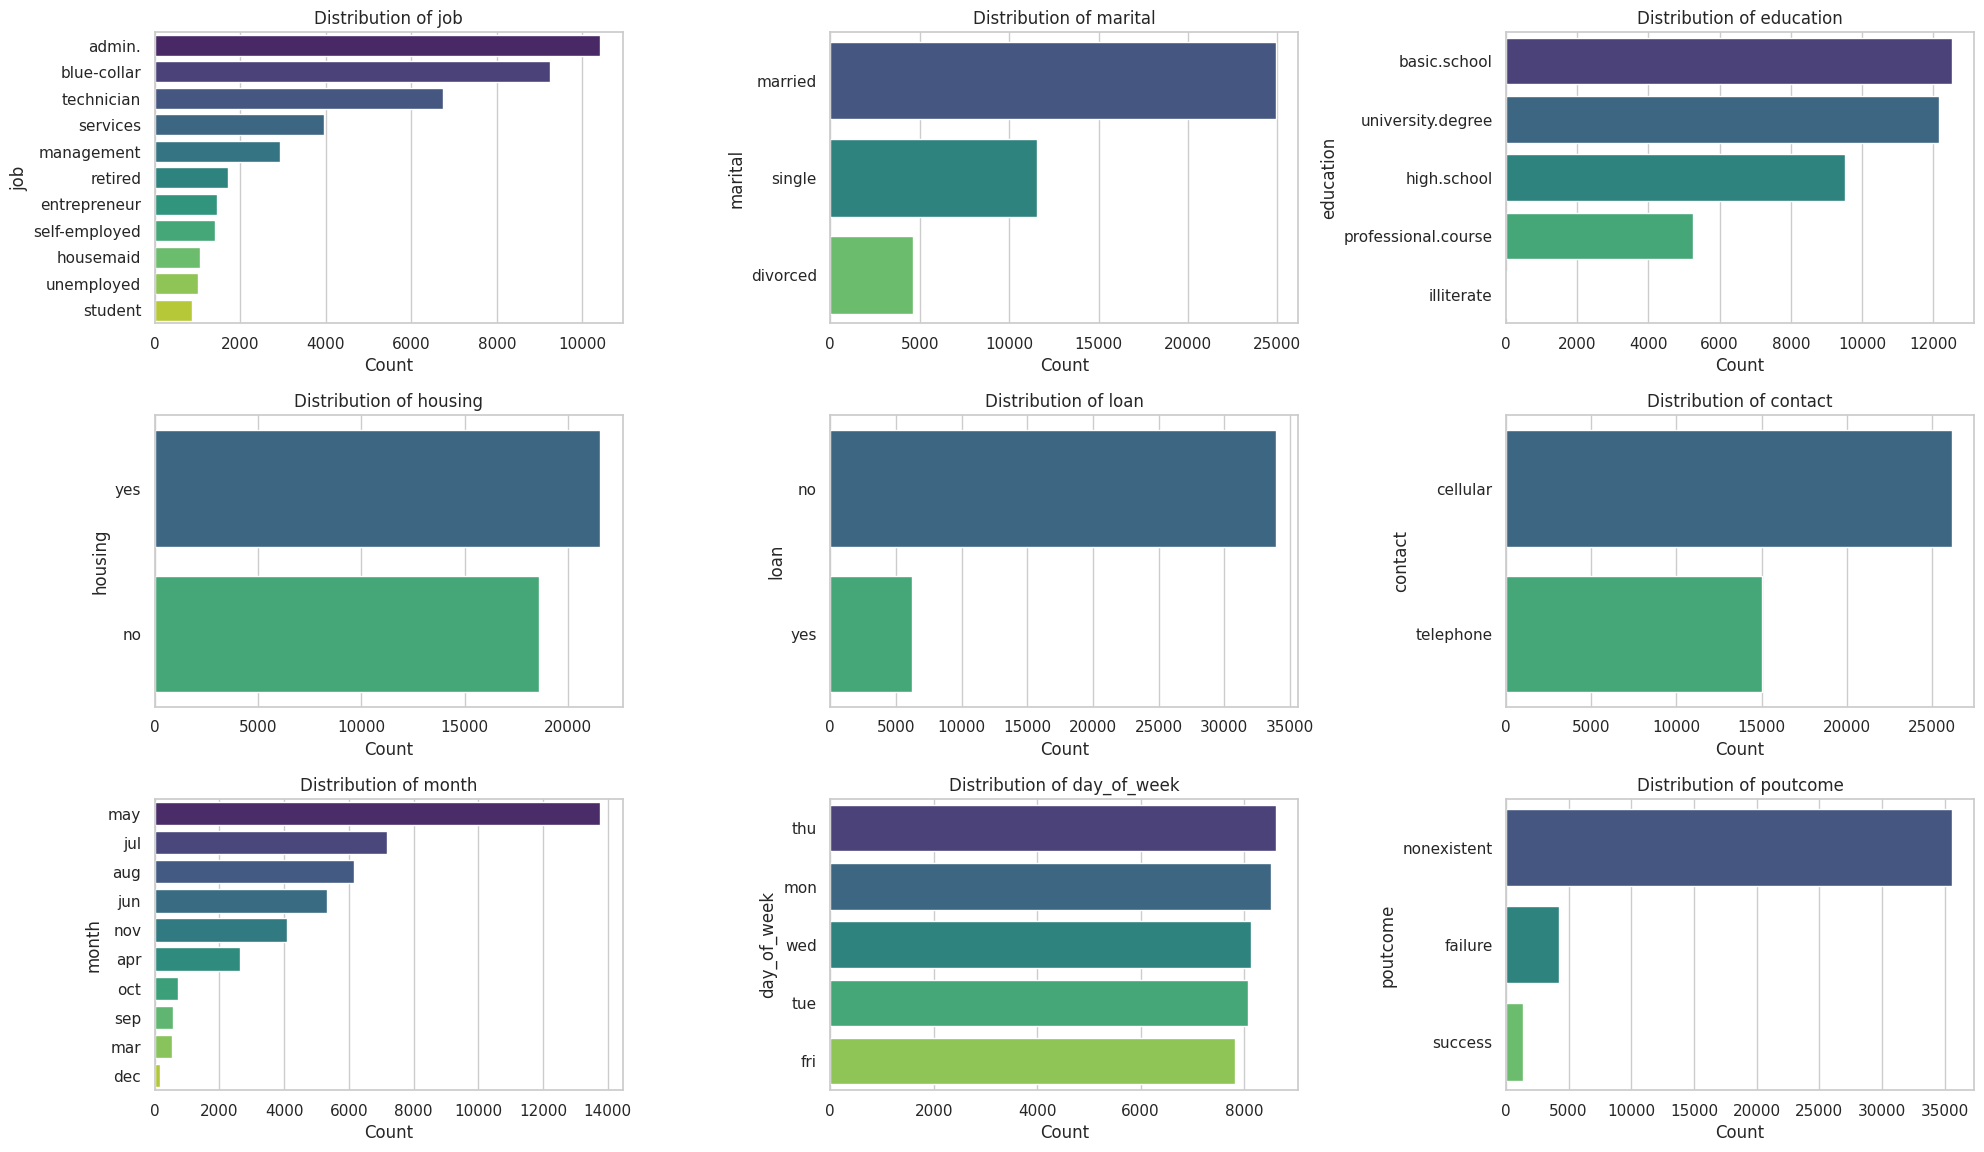

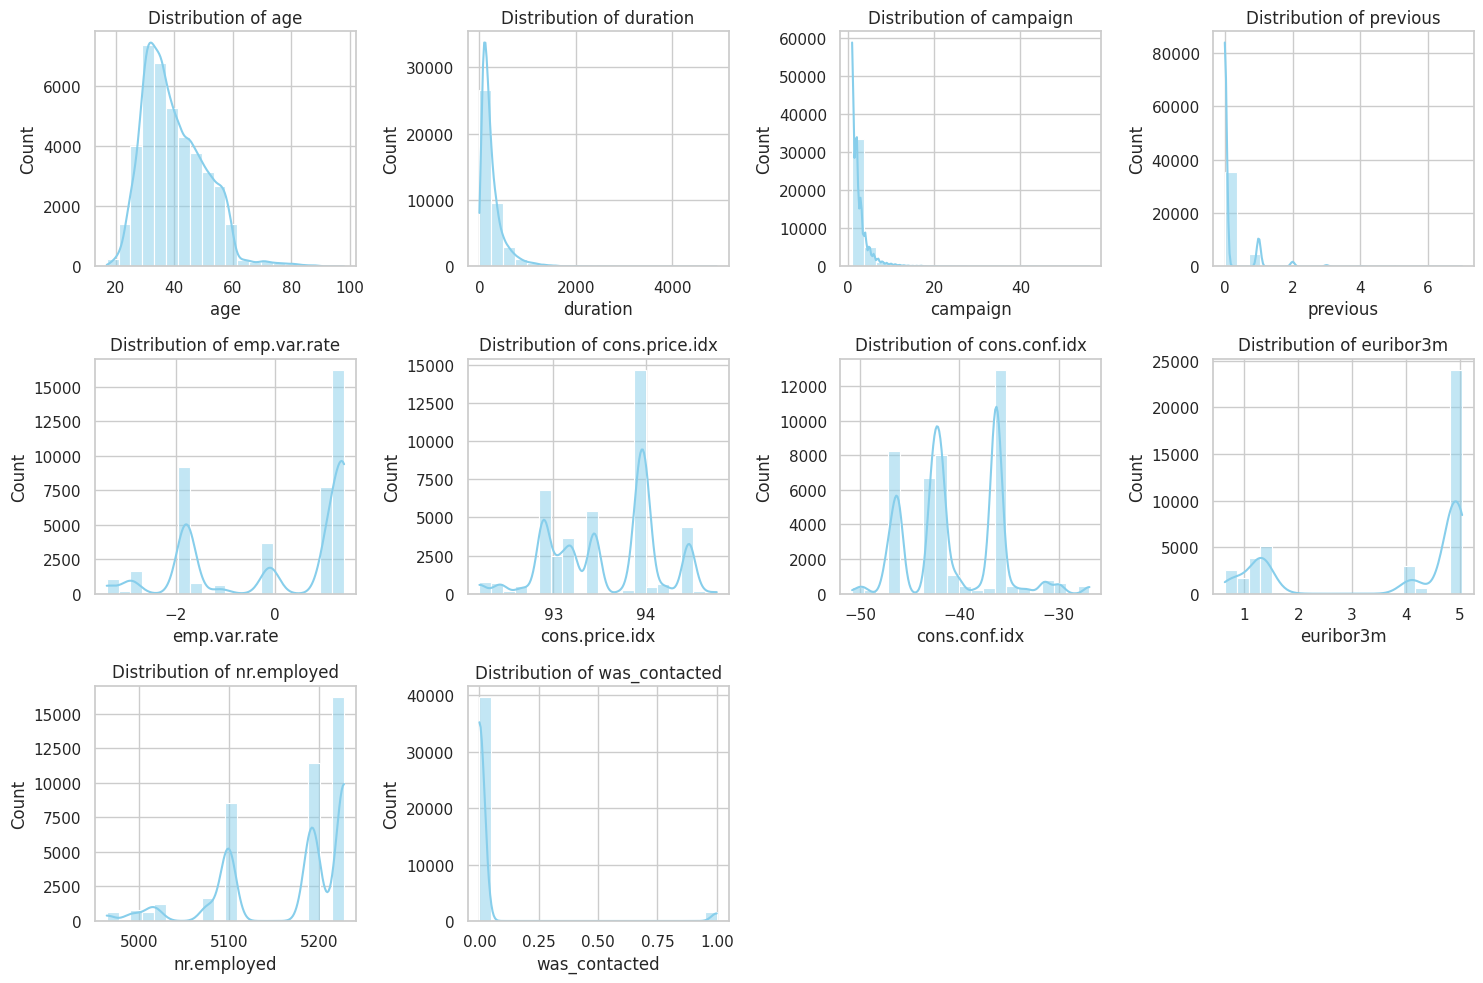

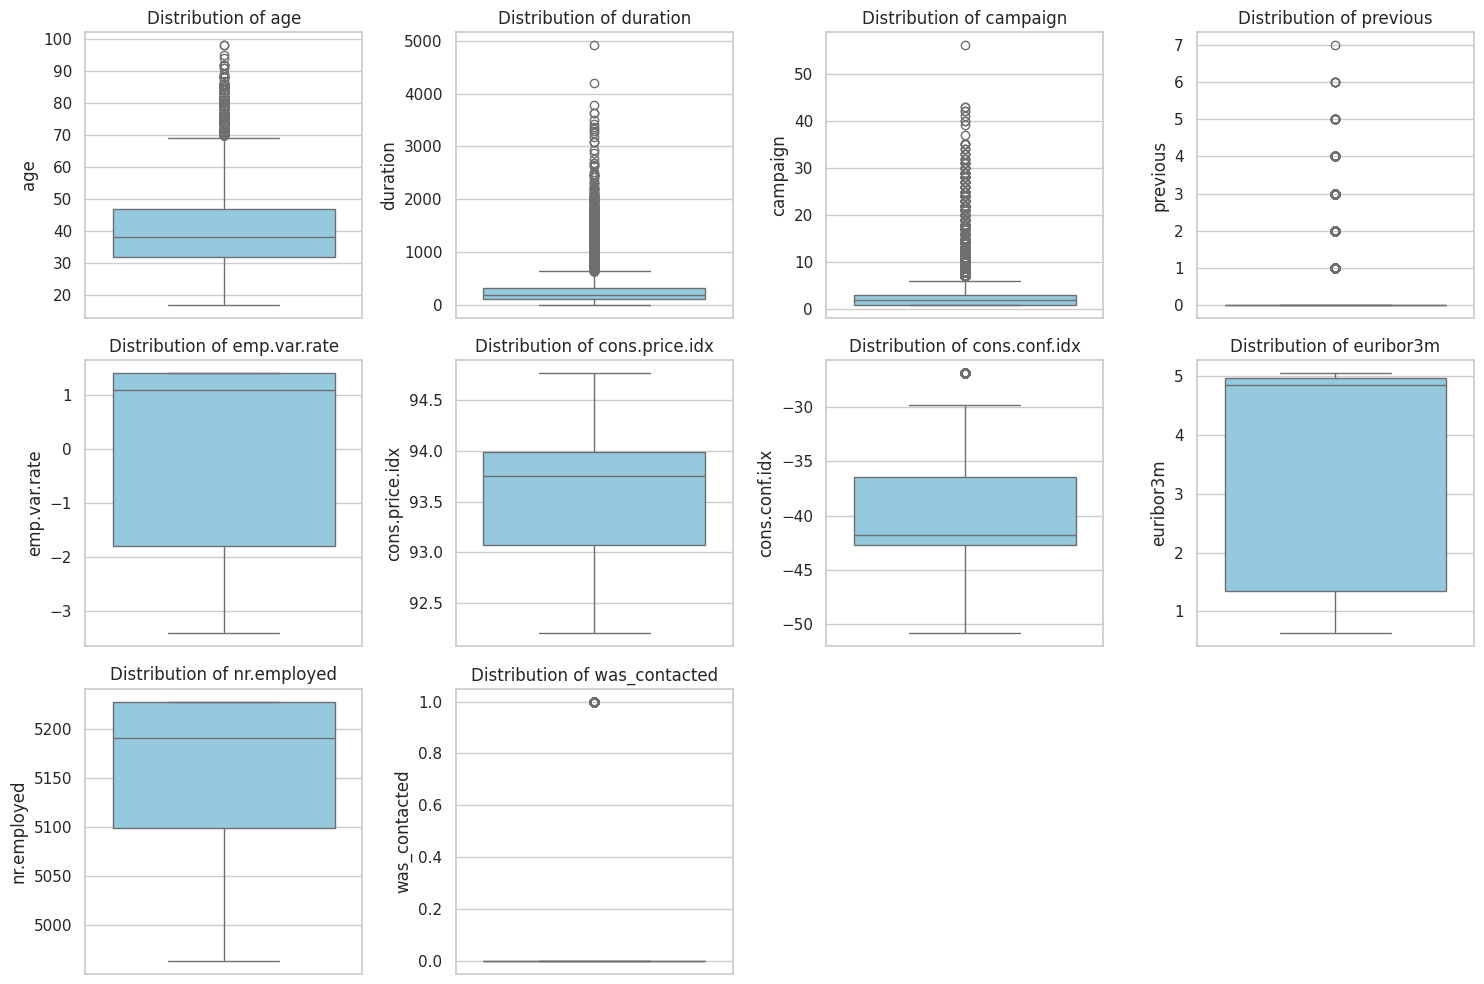

In [21]:

df['y_num'] = df['y'].map({'yes': 1, 'no': 0}) # Helper for correlation

# Configuration
sns.set(style="whitegrid")
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'y_num' in numerical_cols: numerical_cols.remove('y_num')



# Plot Categorical Distributions
plt.figure(figsize=(20, 15))
for i, col in enumerate(categorical_cols, 1):
    if col != 'y':
        plt.subplot(4, 3, i)
        sns.countplot(y=col, data=df, order=df[col].value_counts().index, palette='viridis')
        plt.title(f'Distribution of {col}')
        plt.xlabel('Count')

plt.tight_layout()
plt.show()

# Plot Numerical Distributions
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df[col], bins=20, kde=True, color='skyblue')
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(df[col], color='skyblue')
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

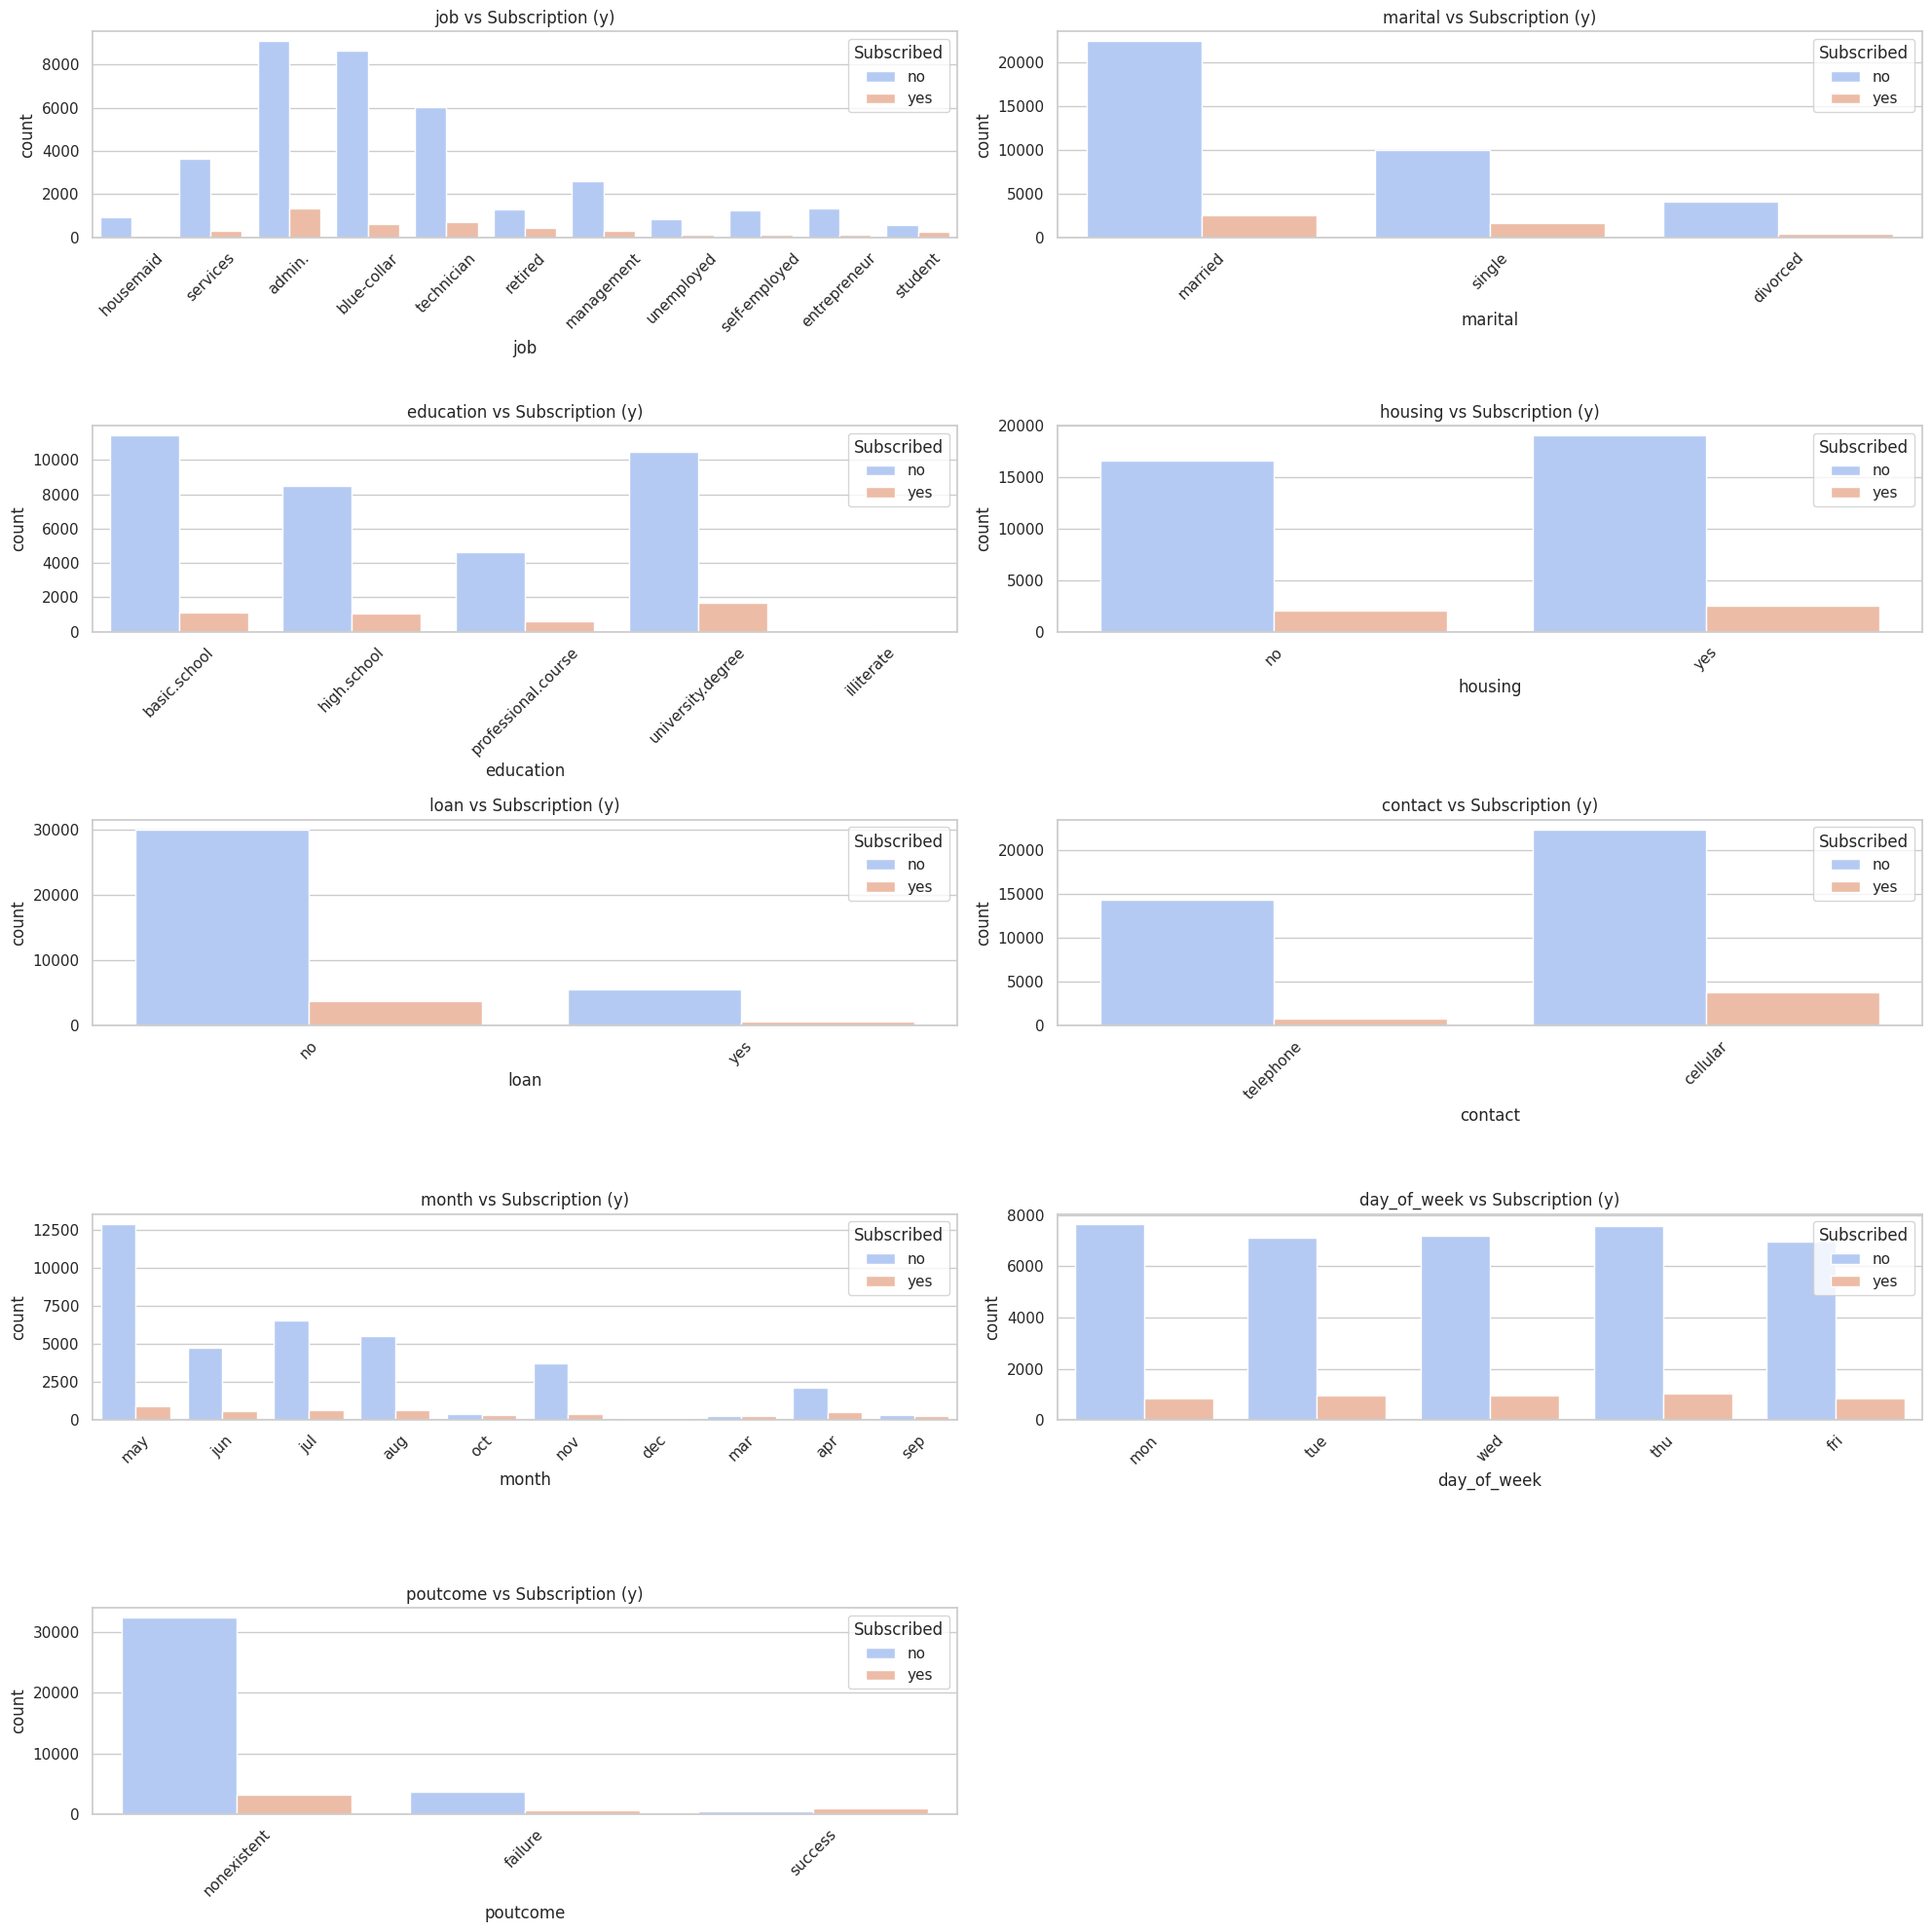

/tmp/ipython-input-3293598336.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y=col, data=df, palette='coolwarm')
/tmp/ipython-input-3293598336.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y=col, data=df, palette='coolwarm')
/tmp/ipython-input-3293598336.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='y', y=col, data=df, palette='coolwarm')
/tmp/ipython-input-3293598336.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to 

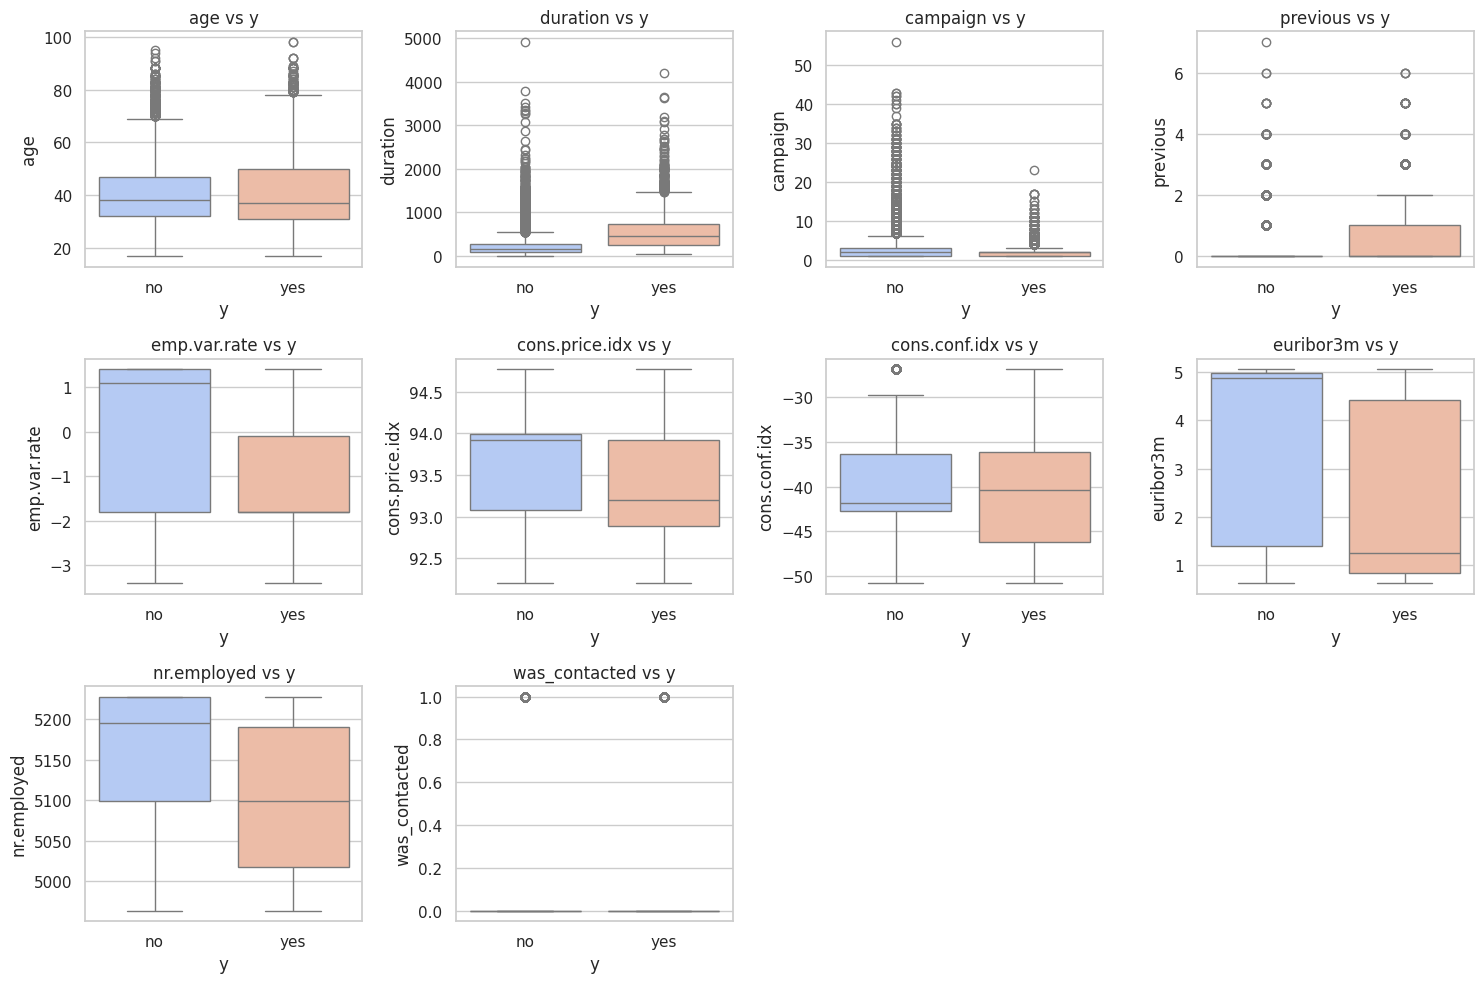

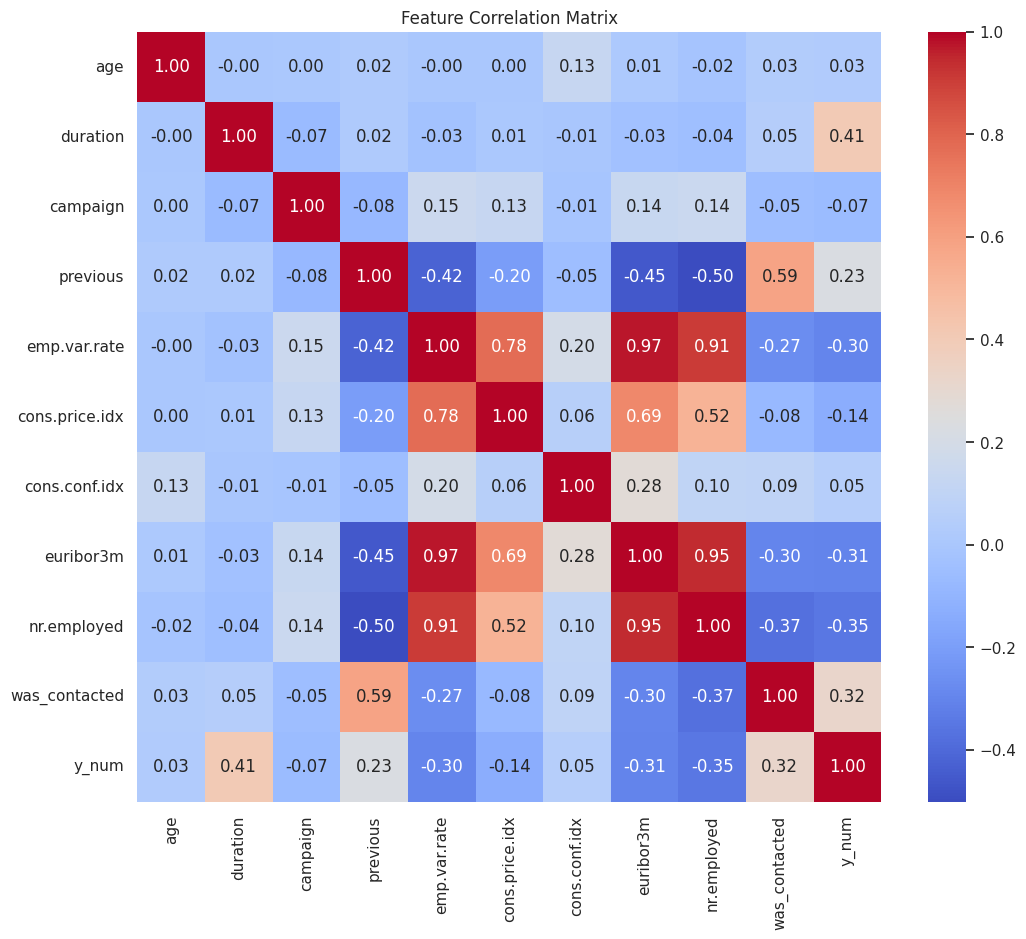

In [22]:
plt.figure(figsize=(20, 20))
for i, col in enumerate(categorical_cols, 1):
    if col != 'y':
        plt.subplot(5, 2, i)
        sns.countplot(x=col, hue='y', data=df, palette='coolwarm')
        plt.title(f'{col} vs Subscription (y)')
        plt.xticks(rotation=45)
        plt.legend(title='Subscribed')

plt.tight_layout()
plt.show()

# Numerical vs Target (Boxplots)
# Shows if the mean value differs for buyers vs non-buyers
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(x='y', y=col, data=df, palette='coolwarm')
    plt.title(f'{col} vs y')

plt.tight_layout()
plt.show()

# Correlation Matrix (Numerical only)
plt.figure(figsize=(12, 10))

corr = df[numerical_cols + ['y_num']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Feature Correlation Matrix')
plt.show()

Target variable is highly imbalanced: most clients do not subscribe, which must be handled during modeling.

Client profile (Univariate): majority are married, working in admin/blue-collar roles, with basic to university education; most have no default or personal loan and are contacted via cellular.

Job: Admin, technician, management show relatively higher subscription counts; students and unemployed remain very low.

Marital: Single clients have a slightly higher subscription rate than married; divorced is minimal.

Education: University degree clients show the highest subscription tendency; professional course and illiterate are lowest.

Housing: Subscription occurs in both groups; housing loan does not strongly block subscription.

Loan: Clients without personal loans are far more likely to subscribe.

Contact: Cellular contact leads to significantly more subscriptions than telephone.

Month: Subscriptions peak in May, followed by summer months; very low in winter.

Day of Week: Subscriptions are fairly even; slightly higher mid-week (Wed–Thu).

Poutcome: Previous success strongly increases likelihood of subscription; nonexistent dominates but converts poorly.

Age: Subscribers are slightly older on average, but difference is small.

Duration: Strong separation — longer calls → much higher subscription.

Campaign: Fewer contacts are associated with higher success; many contacts correlate with rejection.

Previous: Clients contacted previously are more likely to subscribe.

emp.var.rate: Subscriptions occur more during lower employment growth periods.

cons.price.idx: Slightly lower values for subscribers, weak effect.

cons.conf.idx: Subscribers tend to appear when consumer confidence is more negative.

euribor3m: Lower interest rates are associated with higher subscription.

nr.employed: Lower employment levels align with higher subscription rates.

was_contacted: Prior contact increases likelihood of subscription.

Duration has the strongest positive correlation with subscription (y), indicating longer calls are much more likely to result in success ( potential data leakage).

Macroeconomic variables (emp.var.rate, euribor3m, nr.employed) are highly positively correlated with each other, showing strong multicollinearity.

These same economic variables show a moderate negative correlation with subscription, meaning subscriptions are more common during weaker economic conditions.

Previous contact indicators (previous, was_contacted) have positive correlations with y, suggesting prior interaction improves conversion.

Campaign count has a weak negative relationship with subscription, implying repeated calls reduce success.

Age and consumer indices exhibit very weak correlations, contributing little linear predictive power.

# Model Preparation

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             41176 non-null  int64   
 1   job             40846 non-null  object  
 2   marital         41096 non-null  object  
 3   education       39446 non-null  object  
 4   housing         40186 non-null  object  
 5   loan            40186 non-null  object  
 6   contact         41176 non-null  object  
 7   month           41176 non-null  object  
 8   day_of_week     41176 non-null  object  
 9   duration        41176 non-null  int64   
 10  campaign        41176 non-null  int64   
 11  previous        41176 non-null  int64   
 12  poutcome        41176 non-null  object  
 13  emp.var.rate    41176 non-null  float64 
 14  cons.price.idx  41176 non-null  float64 
 15  cons.conf.idx   41176 non-null  float64 
 16  euribor3m       41176 non-null  float64 
 17  nr.employed     4

In [24]:
cols_to_drop = ['y', 'y_num', 'duration']


X = df.drop(columns=cols_to_drop, errors='ignore')
y = df['y_num']


numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()



In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [27]:

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical: Fill missing with 'unknown' then Encode
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

# Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# MODEL


--- Starting Grid Search Experiment ---
Running: Baseline (No SMOTE) + LogisticRegression...
Running: Baseline (No SMOTE) + RandomForest...
Running: Baseline (No SMOTE) + XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [14:43:25] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Running: SMOTE + LogisticRegression...
Running: SMOTE + RandomForest...
Running: SMOTE + XGBoost...


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [14:45:56] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



====== FINAL RESULTS LEADERBOARD ======
             Balancing               Model  F1-Score    Recall  Precision
4                SMOTE        RandomForest  0.520057  0.593750   0.462636
5                SMOTE             XGBoost  0.519115  0.556034   0.486792
3                SMOTE  LogisticRegression  0.459977  0.659483   0.353145
1  Baseline (No SMOTE)        RandomForest  0.395572  0.288793   0.627635
2  Baseline (No SMOTE)             XGBoost  0.356649  0.250000   0.621984
0  Baseline (No SMOTE)  LogisticRegression  0.319805  0.212284   0.648026

Winner: SMOTE_RandomForest with F1-Score: 0.5201


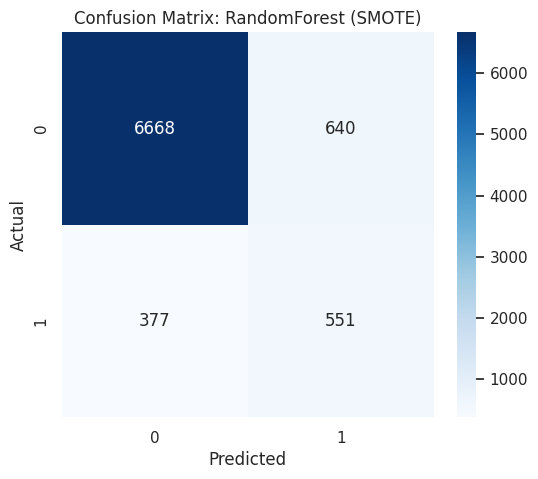

In [28]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'RandomForest': RandomForestClassifier(random_state=42),
    'XGBoost': xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

# Hyperparameter Grids (GridSearch)
param_grids = {
    'LogisticRegression': {
        'classifier__C': [0.1, 1, 10]
    },
    'RandomForest': {
        'classifier__n_estimators': [50, 100],
        'classifier__max_depth': [10, 20, None]
    },
    'XGBoost': {
        'classifier__n_estimators': [50, 100],
        'classifier__learning_rate': [0.01, 0.1],
        'classifier__max_depth': [3, 6]
    }
}

# Balancing Strategies
# Tuple format: (Name, BalancerObject)
balancing_strategies = [
    ('Baseline (No SMOTE)', None),
    ('SMOTE', SMOTE(random_state=42))
]

# MAIN EXECUTION
results_data = []
best_estimators = {}



for bal_name, balancer in balancing_strategies:
    for model_name, model_obj in models.items():
        print(f"Running: {bal_name} + {model_name}...")

        # Build Pipeline
        # Structure: Preprocess -> (Optional Resample) -> Classifier
        steps = [('preprocessor', preprocessor)]

        if balancer:
            steps.append(('resampler', balancer))

        steps.append(('classifier', model_obj))

        pipeline = ImbPipeline(steps=steps)

        # Setup GridSearch
        # Note: 'classifier__' prefix in param_grids matches the step name 'classifier'
        grid = GridSearchCV(
            pipeline,
            param_grids[model_name],
            cv=3,              # 3-Fold Cross Validation
            scoring='f1',      # Optimize for F1 Score (since data is imbalanced)
            n_jobs=-1          # Use all CPU cores
        )

        # Fit GridSearch (Trains multiple models and finds the best)
        grid.fit(X_train, y_train)

        # Evaluate Best Model on Test Set
        best_model = grid.best_estimator_
        y_pred = best_model.predict(X_test)

        # Store Results
        results_data.append({
            'Balancing': bal_name,
            'Model': model_name,
            'Best_Params': str(grid.best_params_),
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'F1-Score': f1_score(y_test, y_pred),
            'AUC': roc_auc_score(y_test, y_pred)
        })

        # Save model
        best_estimators[f"{bal_name}_{model_name}"] = best_model

# result
results_df = pd.DataFrame(results_data)
results_df = results_df.sort_values(by='F1-Score', ascending=False)

print("\n====== FINAL RESULTS LEADERBOARD ======")
print(results_df[['Balancing', 'Model', 'F1-Score', 'Recall', 'Precision']])

# VISUALIZE WINNER
winner = results_df.iloc[0]
winner_key = f"{winner['Balancing']}_{winner['Model']}"
print(f"\nWinner: {winner_key} with F1-Score: {winner['F1-Score']:.4f}")

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, best_estimators[winner_key].predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Confusion Matrix: {winner['Model']} ({winner['Balancing']})")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Selected model & evaluation

In [29]:
print(winner['Best_Params'])

{'classifier__max_depth': 10, 'classifier__n_estimators': 50}


In [ ]:
print(classification_report(y_test, best_estimators[winner_key].predict(X_test)))

              precision    recall  f1-score   support

           0       0.95      0.91      0.93      7308
           1       0.46      0.59      0.52       928

    accuracy                           0.88      8236
   macro avg       0.70      0.75      0.72      8236
weighted avg       0.89      0.88      0.88      8236




Winning Model: SMOTE + RandomForest
F1-Score: 0.5201
Recall: 0.5938
Precision: 0.4626
AUC: 0.7531


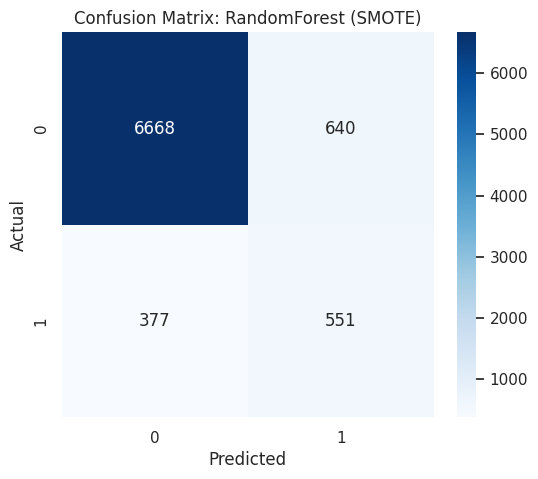

In [ ]:
print(f"\nWinning Model: {winner['Balancing']} + {winner['Model']}")
print(f"F1-Score: {winner['F1-Score']:.4f}")
print(f"Recall: {winner['Recall']:.4f}")
print(f"Precision: {winner['Precision']:.4f}")
print(f"AUC: {winner['AUC']:.4f}")

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, best_estimators[winner_key].predict(X_test))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Confusion Matrix: {winner['Model']} ({winner['Balancing']})")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

/tmp/ipython-input-2439646399.py:15: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "k--" (-> linestyle='--'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', label='Random Chance', linestyle='--')


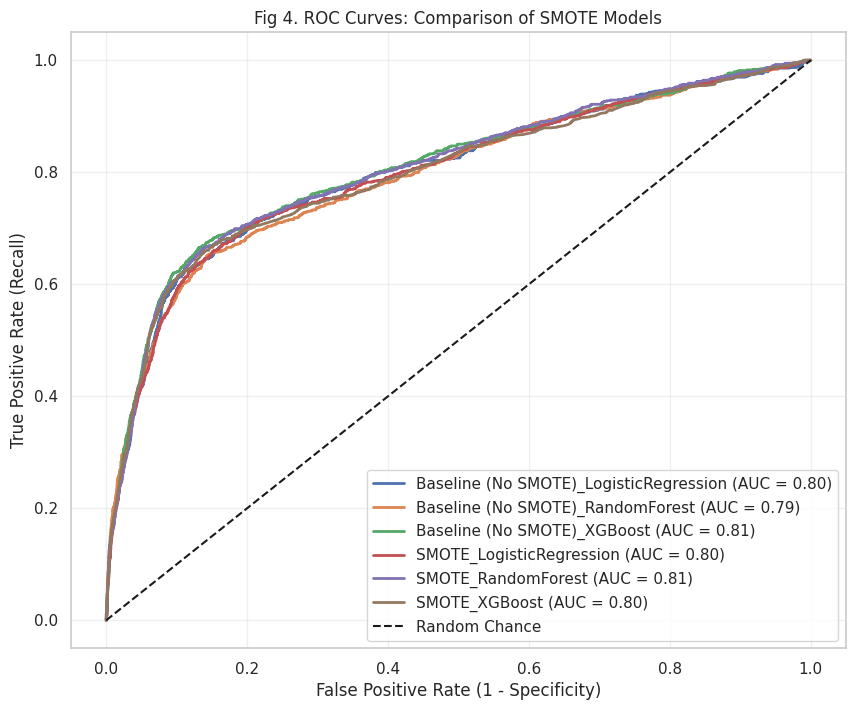

In [30]:
# ROC CURVE COMPARISON
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 8))



for name, model in best_estimators.items():
    if 'SMOTE' in name: # Filter to show only SMOTE models (cleaner plot)
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc_score = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.2f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance', linestyle='--')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Fig 4. ROC Curves: Comparison of SMOTE Models')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

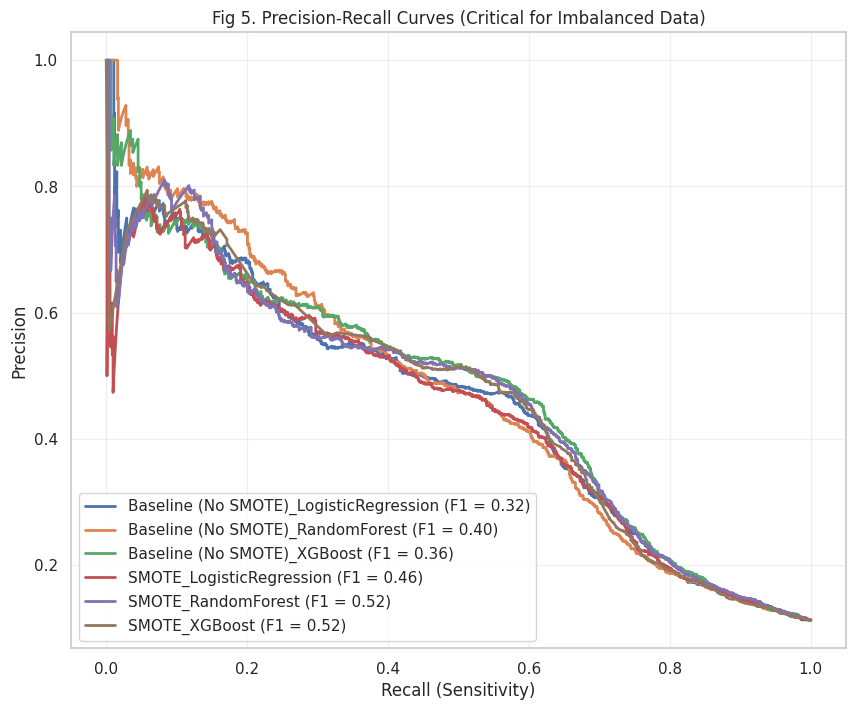

In [31]:
# PRECISION-RECALL CURVE
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(10, 8))

for name, model in best_estimators.items():
    if 'SMOTE' in name:
        y_proba = model.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        f1 = f1_score(y_test, model.predict(X_test))
        plt.plot(recall, precision, label=f'{name} (F1 = {f1:.2f})', linewidth=2)

plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision')
plt.title('Fig 5. Precision-Recall Curves (Critical for Imbalanced Data)')
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
# COST-SENSITIVE ANALYSIS
print("\n" + "="*40)
print("BUSINESS IMPACT & COST ANALYSIS")
print("="*40)


cost_fn = 200  # Cost of losing a customer (High)
cost_fp = 1    # Cost of a wasted call (Low)

# Compare the Winner vs. Standard model
models_to_compare = [
    'Baseline (No SMOTE)_RandomForest',
    winner_key
]

for key in models_to_compare:
    if key in best_estimators:
        y_pred = best_estimators[key].predict(X_test)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

        # Calculate Total Cost
        total_cost = (fn * cost_fn) + (fp * cost_fp)

        print(f"\nModel: {key}")
        print(f"Missed Customers (FN): {fn} (Cost: ${fn * cost_fn:,})")
        print(f"Wasted Calls     (FP): {fp} (Cost: ${fp * cost_fp:,})")
        print(f"TOTAL BUSINESS COST:   ${total_cost:,.2f}")

print("\n(Lower Total Cost is Better. This proves High Recall saves money.)")


BUSINESS IMPACT & COST ANALYSIS

Model: Baseline (No SMOTE)_RandomForest
Missed Customers (FN): 660 (Cost: $132,000)
Wasted Calls     (FP): 159 (Cost: $159)
TOTAL BUSINESS COST:   $132,159.00

Model: SMOTE_RandomForest
Missed Customers (FN): 377 (Cost: $75,400)
Wasted Calls     (FP): 640 (Cost: $640)
TOTAL BUSINESS COST:   $76,040.00

(Lower Total Cost is Better. This proves High Recall saves money.)


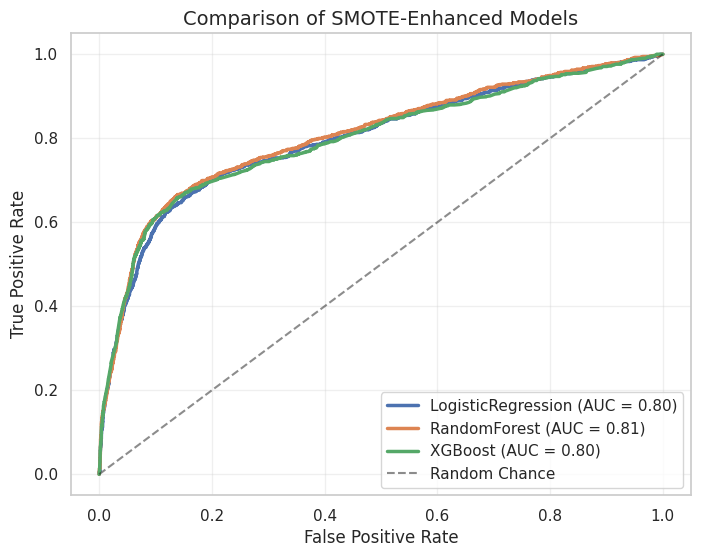

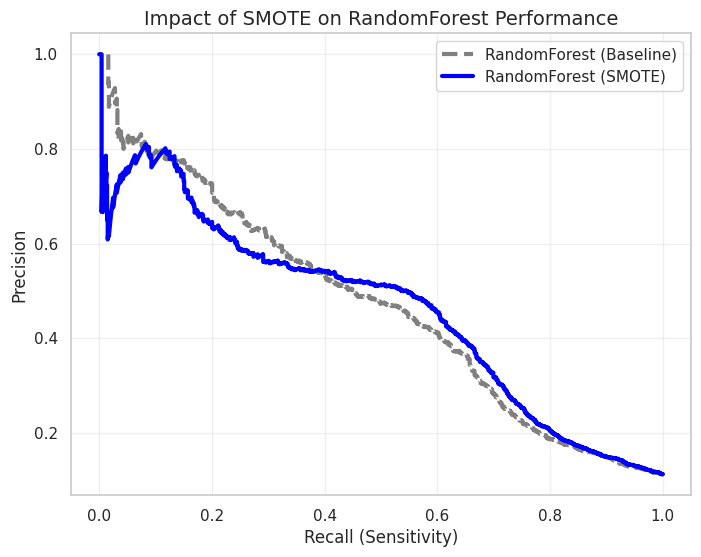

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, f1_score

plt.figure(figsize=(8, 6))

for name, model in best_estimators.items():

    if name.startswith('SMOTE'):
        y_proba = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f'{name.replace("SMOTE_", "")} (AUC = {auc:.2f})', linewidth=2.5)

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance', alpha=0.5)
plt.title('Comparison of SMOTE-Enhanced Models', fontsize=14)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

# IMPACT ANALYSIS (RF Baseline vs RF SMOTE)
plt.figure(figsize=(8, 6))

target_algo = 'RandomForest'

for name, model in best_estimators.items():
    if target_algo in name:
        y_proba = model.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, y_proba)

        # Style beda untuk Baseline vs SMOTE
        if 'Baseline' in name:
            style = '--' # Garis putus-putus untuk Baseline
            label = f'{target_algo} (Baseline)'
            color = 'gray'
        else:
            style = '-'  # Garis tegas untuk SMOTE
            label = f'{target_algo} (SMOTE)'
            color = 'blue'

        plt.plot(recall, precision, linestyle=style, label=label, color=color, linewidth=3)

plt.title(f'Impact of SMOTE on {target_algo} Performance', fontsize=14)
plt.xlabel('Recall (Sensitivity)')
plt.ylabel('Precision')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

/tmp/ipython-input-4136828073.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


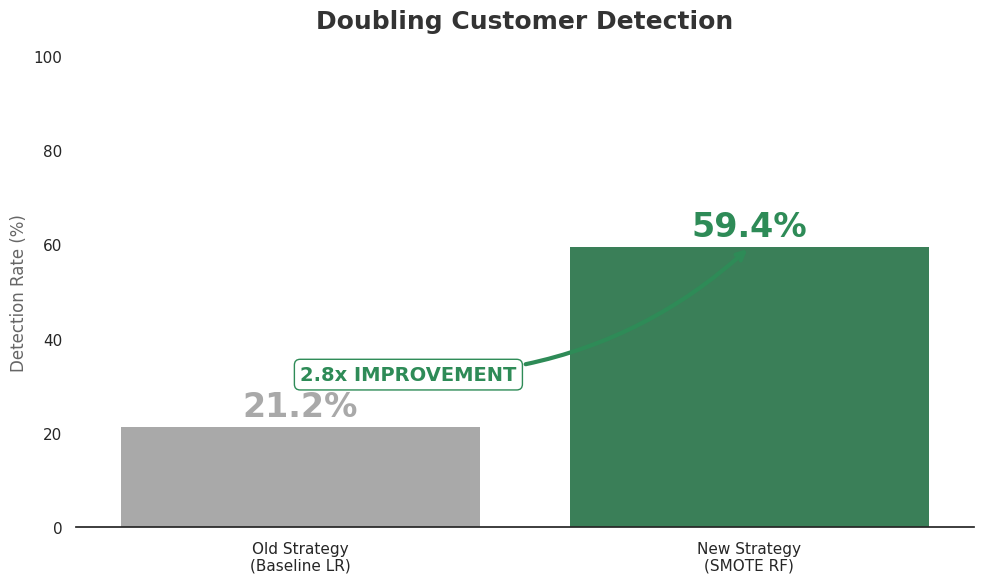

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


# Extract Recall values for the standard model(baseline logreg) and the winner
baseline_recall = results_df[(results_df['Balancing'] == 'Baseline (No SMOTE)') & (results_df['Model'] == 'LogisticRegression')]['Recall'].values[0] * 100
smote_recall = results_df[(results_df['Balancing'] == 'SMOTE') & (results_df['Model'] == 'RandomForest')]['Recall'].values[0] * 100

# Calculate Improvement Factor
improvement = smote_recall / baseline_recall

# Prepare Data for Plotting
plot_data = pd.DataFrame({
    'Model': ['Old Strategy\n(Baseline LR)', 'New Strategy\n(SMOTE RF)'],
    'Detection Rate': [baseline_recall, smote_recall]
})

# PLOT
sns.set_style("white")
plt.figure(figsize=(10, 6))
colors = ['#A9A9A9', '#2E8B57'] # Grey vs Green

ax = sns.barplot(
    x='Model',
    y='Detection Rate',
    data=plot_data,
    palette=colors,
    edgecolor="none"
)

# STYLING & LABELS
sns.despine(left=True, bottom=False)
plt.title('Doubling Customer Detection', fontsize=18, fontweight='bold', pad=20, color='#333333')
plt.ylabel('Detection Rate (%)', fontsize=12, color='#666666')
plt.xlabel('')
plt.yticks(range(0, 101, 20))

# Add Dynamic Text Labels
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.,
        height + 1,
        f'{height:.1f}%', # Uses actual float value
        ha="center", va="bottom",
        fontsize=24, fontweight='bold', color=colors[i]
    )

# Add Dynamic Arrow
plt.annotate(
    f'{improvement:.1f}x IMPROVEMENT',
    xy=(1, smote_recall),
    xytext=(0, baseline_recall + 10),
    arrowprops=dict(arrowstyle="->", color='#2E8B57', lw=3, connectionstyle="arc3,rad=0.2"),
    fontsize=14, color='#2E8B57', fontweight='bold',
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#2E8B57", lw=1)
)

plt.tight_layout()
plt.show()